# 02 · Três métodos de seleção de atributos e votação

Passos **4 e 5 do fluxo único**. Os três métodos rodam **neste mesmo notebook**, sobre os dados de **treino** do ciclo (pré-processados pelo `ColumnTransformer` ajustado no treino):

1. **SelectKBest** com informação mútua (`mutual_info_classif`) — estatística adequada a alvo multiclasse e atributos contínuos/binários, capta relações não lineares;
2. **Importância de Random Forest** (MDI, classes balanceadas) — capta interações;
3. **RFE** com **Regressão Logística** multinomial — visão linear e multivariada (por isso os dados são padronizados).

A **regra de votação foi definida antes da comparação** em `config/config.yaml` e é registrada no MLflow.

In [1]:
import sys
from pathlib import Path

# Caminhos consistentes: localiza a raiz do projeto (pasta com config/config.yaml)
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "config.yaml").exists())
sys.path.insert(0, str(RAIZ))
from src.config import preparar_notebook

cfg = preparar_notebook()  # muda o diretório de trabalho para a raiz do projeto

import json

import joblib
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 80, "figure.figsize": (9, 4)})

from sklearn.model_selection import StratifiedKFold

from src import ciclo, rastreamento
from src import features as fs
from src import preprocessamento as pp
from src.config import ler_json, salvar_json
from src.modelagem import codificar_alvo

ctx = ciclo.carregar_ciclo(exigir=["01_etl"])
EVID = ciclo.dir_evidencias(ctx)
print(f"cycle_id = {ctx['cycle_id']}  |  data_version = {ctx['data_version']}")

cycle_id = c0009-20261127T185643Z  |  data_version = dv009-d59b5486


In [2]:
regra = cfg["votacao"]
display(Markdown(f"""
**Regra de votação (a priori):** cada método elege seu **top-{regra['top_k']}**; uma feature é eleita se receber
**≥ {regra['votos_minimos']} votos de 3**. Quantidade mínima **{regra['min_features']}** (completada pelo menor rank médio)
e máxima **{regra['max_features']}** (corte pelo maior rank médio). Desempate: **{regra['desempate']}**, depois ordem alfabética.
MI e RFE usam amostra estratificada de até {regra['amostra_maxima']:,} linhas do treino (custo computacional).
"""))


**Regra de votação (a priori):** cada método elege seu **top-30**; uma feature é eleita se receber
**≥ 2 votos de 3**. Quantidade mínima **20** (completada pelo menor rank médio)
e máxima **36** (corte pelo maior rank médio). Desempate: **rank_medio**, depois ordem alfabética.
MI e RFE usam amostra estratificada de até 15,000 linhas do treino (custo computacional).


In [3]:
base = pd.read_parquet(Path(cfg["dados"]["dir_processed"]) / "base_features.parquet")
treino = base[base["particao"] == "treino"].reset_index(drop=True)
X_treino = treino[pp.COLUNAS_FEATURES]
y_treino = codificar_alvo(treino["type"], cfg["dados"]["classes"])
prep = joblib.load(Path(cfg["dados"]["dir_processed"]) / "preprocessador_treino.joblib")
Xt = prep.transform(X_treino)
semente = cfg["avaliacao"]["semente"]
print(f"Treino: {Xt.shape[0]:,} linhas x {Xt.shape[1]} colunas candidatas")

votacao = fs.executar_votacao(Xt, y_treino, cfg, semente)
print("Tempo por método (s):", votacao["tempos_s"])

Treino: 48,663 linhas x 56 colunas candidatas


Tempo por método (s): {'selectkbest': 2.57, 'random_forest': 2.43, 'rfe': 89.07}


### Rankings de cada método (top-15)

In [4]:
lado_a_lado = pd.concat(
    {m: df.head(15)[["feature", "importancia"]].reset_index(drop=True) for m, df in votacao["rankings"].items()}, axis=1
)
lado_a_lado.index = lado_a_lado.index + 1
display(lado_a_lado.round(4))

selectkbest                   random_forest                          rfe            
            feature importancia             feature importancia          feature importancia
1      ratio_digits      0.1693              kw_cms      0.0692          tld_edu      1.7407
2            kw_cms      0.1682       ratio_letters      0.0663           tld_ca      1.2474
3     ratio_letters      0.1631          kw_malware      0.0648          tld_gov      1.1212
4       path_length      0.1580        ratio_digits      0.0594           tld_uk      1.0959
5     ratio_special      0.1121      digits_in_host      0.0493          tld_org      1.0415
6     num_ampersand      0.1100  has_exec_extension      0.0447           tld_br      1.0271
7        num_params      0.1096          num_digits      0.0368        num_slash      1.0107
8      query_length      0.1069          num_params      0.0365       path_depth      0.9481
9         num_equal      0.1033           num_equal      0.0290         tld_info      0.9024
10          entropy      0.1025         path_length      0.0288  num_path_tokens      0.8501
11  num_path_tokens      0.1018     num_path_tokens      0.0287           tld_au      0.8441
12      num_letters      0.1016         num_letters      0.0282          tld_net      0.8150
13      num_special      0.0879          url_length      0.0277           tld_ru      0.8019
14       url_length      0.0815       ratio_special      0.0269           kw_cms      0.7883
15       num_digits      0.0805             tld_com      0.0258          tld_com      0.7874

### Tabela de votos e features eleitas do ciclo

,feature,votos,eleita,motivo,rank_medio,voto_selectkbest,voto_random_forest,voto_rfe,rank_selectkbest,rank_random_forest,rank_rfe,importancia_selectkbest,importancia_random_forest,importancia_rfe
0,kw_cms,3,True,maioria (2+ votos),5.67,1,1,1,2,1,14,0.17,0.07,0.79
1,num_path_tokens,3,True,maioria (2+ votos),10.67,1,1,1,11,11,10,0.10,0.03,0.85
2,num_params,3,True,maioria (2+ votos),11.33,1,1,1,7,8,19,0.11,0.04,0.64
3,num_equal,3,True,maioria (2+ votos),14.33,1,1,1,9,9,25,0.10,0.03,0.44
4,num_ampersand,3,True,maioria (2+ votos),16.33,1,1,1,6,19,24,0.11,0.02,0.44
5,path_depth,3,True,maioria (2+ votos),16.67,1,1,1,16,26,8,0.07,0.02,0.95
6,num_special,3,True,maioria (2+ votos),17.33,1,1,1,13,21,18,0.09,0.02,0.74
7,tld_com,3,True,maioria (2+ votos),17.67,1,1,1,23,15,15,0.06,0.03,0.79
8,digits_in_host,3,True,maioria (2+ votos),18.33,1,1,1,20,5,30,0.07,0.05,0.33
9,num_slash,3,True,maioria (2+ votos),18.67,1,1,1,22,27,7,0.06,0.02,1.01


29 features eleitas: ['kw_cms', 'num_path_tokens', 'num_params', 'num_equal', 'num_ampersand', 'path_depth', 'num_special', 'tld_com', 'digits_in_host', 'num_slash', 'has_exec_extension', 'has_ip', 'num_hyphen', 'ratio_digits', 'ratio_letters', 'ratio_special', 'num_letters', 'num_digits', 'path_length', 'entropy', 'url_length', 'kw_malware', 'num_dots', 'query_length', 'ext_php', 'num_suspicious_words', 'has_query', 'tld_ip', 'longest_token']


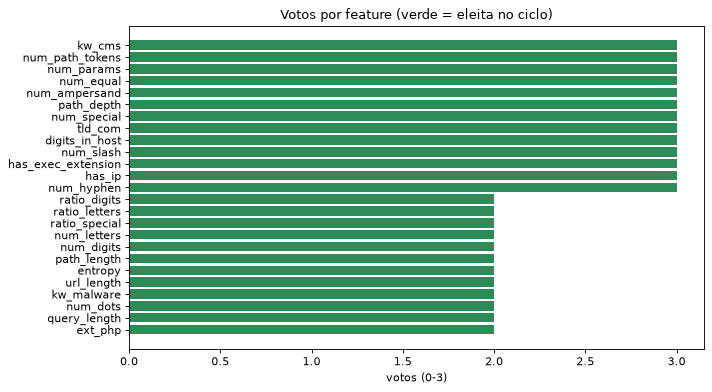

In [5]:
tabela = votacao["tabela"]
eleitas = votacao["eleitas"]
display(tabela.head(25).round(2))
print(f"{len(eleitas)} features eleitas: {eleitas}")

fig, ax = plt.subplots(figsize=(9, 5))
top = tabela.head(25).iloc[::-1]
cores = ["#2E8B57" if e else "#B0B0B0" for e in top["eleita"]]
ax.barh(top["feature"], top["votos"], color=cores)
ax.set_xlabel("votos (0-3)"); ax.set_title("Votos por feature (verde = eleita no ciclo)")
fig.tight_layout(); fig.savefig(EVID / "votacao_votos.png"); plt.show()

### Votação dentro de cada fold (sem vazamento na validação cruzada)

Para que a validação cruzada do notebook 03 não use informação dos folds de validação, o pré-processamento **e** os três métodos + votação são refeitos **dentro de cada fold**, apenas com a parte de treino do fold. As mesmas features por fold são usadas pelos dois algoritmos. A estabilidade mostra o quanto a seleção é robusta.

In [6]:
skf = StratifiedKFold(n_splits=cfg["avaliacao"]["cv_folds"], shuffle=True, random_state=semente)
folds = np.zeros(len(X_treino), dtype=int)
for f, (_, idx_val) in enumerate(skf.split(X_treino, y_treino)):
    folds[idx_val] = f
por_fold = fs.votacao_por_fold(X_treino, y_treino, folds, cfg, semente)
eleitas_por_fold = {f: r["eleitas"] for f, r in por_fold.items()}
estab = fs.estabilidade(eleitas_por_fold, eleitas)
print(f"Jaccard médio entre folds: {estab['jaccard_medio_entre_folds']:.3f} | vs. conjunto do ciclo: {estab['jaccard_medio_vs_ciclo']:.3f}")
display(pd.Series(estab["frequencia_eleicao"], name=f"folds em que foi eleita (de {len(por_fold)})").to_frame().T)

Jaccard médio entre folds: 0.905 | vs. conjunto do ciclo: 0.936


,digits_in_host,entropy,ext_php,has_exec_extension,has_ip,has_query,kw_cms,kw_malware,longest_token,num_ampersand,num_digits,num_dots,num_equal,num_letters,num_params,num_path_tokens,num_slash,num_special,path_depth,path_length,query_length,ratio_digits,ratio_letters,ratio_special,tld_com,tld_ip,url_length,num_hyphen,ext_html,host_length,num_suspicious_words,num_question,num_underscore
folds em que foi eleita (de 5),5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,4,2,2,2,1,1


### O que mudou em relação ao ciclo anterior

In [7]:
anteriores = sorted(p for p in Path("evidencias").glob("c*/votacao_features.json") if p.parent.name < ctx["cycle_id"])
if anteriores:
    eleitas_ant = ler_json(anteriores[-1])["eleitas"]
    mudancas = {"ciclo_anterior": anteriores[-1].parent.name, "entraram": sorted(set(eleitas) - set(eleitas_ant)),
                "sairam": sorted(set(eleitas_ant) - set(eleitas)), "jaccard": fs.jaccard(eleitas, eleitas_ant)}
else:
    mudancas = {"ciclo_anterior": None, "entraram": eleitas, "sairam": [], "jaccard": None}
print(mudancas)

{'ciclo_anterior': 'c0008-20261126T185946Z', 'entraram': [], 'sairam': [], 'jaccard': 1.0}


## Registro no MLflow e evidências

In [8]:
np.save(Path(cfg["dados"]["dir_processed"]) / "folds_treino.npy", folds)
tabela.to_csv(EVID / "votacao_tabela.csv", index=False)
for m, df in votacao["rankings"].items():
    df.to_csv(EVID / f"ranking_{m}.csv", index=False)
resultado = {
    "cycle_id": ctx["cycle_id"], "data_version": ctx["data_version"], "metodo_votacao": regra["metodo"],
    "regra": {k: regra[k] for k in ("top_k", "votos_minimos", "min_features", "max_features", "desempate", "amostra_maxima")},
    "metodos": {"selectkbest": "mutual_info_classif", "random_forest": "feature_importances_ (MDI)", "rfe": "RFE + LogisticRegression"},
    "n_candidatas": int(Xt.shape[1]), "eleitas": eleitas, "tempos_s": votacao["tempos_s"],
    "eleitas_por_fold": eleitas_por_fold, "estabilidade": estab, "mudancas": mudancas,
}
salvar_json(resultado, EVID / "votacao_features.json")

with rastreamento.run_etapa(ctx, cfg, "02_votacao_features", "02_votacao") as run:
    mlflow.log_params({"metodo_votacao": regra["metodo"], **{f"regra_{k}": v for k, v in resultado["regra"].items()},
                       "metodo_1": "SelectKBest(mutual_info_classif)", "metodo_2": "RandomForest importance",
                       "metodo_3": "RFE(LogisticRegression)", "rf_n_estimators": regra["metodos"]["random_forest"]["n_estimators"],
                       "rf_max_depth": regra["metodos"]["random_forest"]["max_depth"], "rfe_step": regra["metodos"]["rfe"]["step"],
                       "n_candidatas": Xt.shape[1], "features_eleitas": ",".join(eleitas)})
    mlflow.log_metrics({"n_features_eleitas": len(eleitas), "jaccard_folds": estab["jaccard_medio_entre_folds"],
                        "jaccard_folds_vs_ciclo": estab["jaccard_medio_vs_ciclo"]})
    mlflow.log_metrics({f"votos.{r.feature}": r.votos for r in tabela.itertuples()})
    mlflow.log_dict(resultado, "votacao_features.json")
    for nome in ["votacao_tabela.csv", "ranking_selectkbest.csv", "ranking_random_forest.csv", "ranking_rfe.csv", "votacao_votos.png"]:
        mlflow.log_artifact(str(EVID / nome))
    run_id = run.info.run_id

ctx = ciclo.registrar_etapa(ctx, "02_votacao", run_id=run_id, features_eleitas=eleitas)
print(f"Etapa 02 concluída | {len(eleitas)} features eleitas | run_id={run_id}")

🏃 View run c0009-20261127T185643Z/02_votacao_features at: http://127.0.0.1:5000/#/experiments/1/runs/c85bbd34220a48118b2708d9ff383e5c
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
Etapa 02 concluída | 29 features eleitas | run_id=c85bbd34220a48118b2708d9ff383e5c
